In [53]:
import numpy as np
import cmsisdsp as dsp
import matplotlib.pyplot as plt

In [54]:
def test_signal_func(t: np.array) -> np.ndarray:
    return (
        3.3 * np.sin(2 * np.pi * 10.5 * 1e3 * t)
        + 5.0 * np.sin(2 * np.pi * 21 * 1e3 * t)
        + 2.0 * np.sin(2 * np.pi * 31.5 * 1e3 * t)
        + 1.0 * np.sin(2 * np.pi * 42 * 1e3 * t)
    )

In [55]:
def adc(signal_func, fs: float, n_samples: int) -> np.ndarray:
    timeline = np.linspace(0, n_samples / fs, n_samples)
    return signal_func(timeline)

In [56]:
FS = 1.024e6
N_SAMPLES = 2048

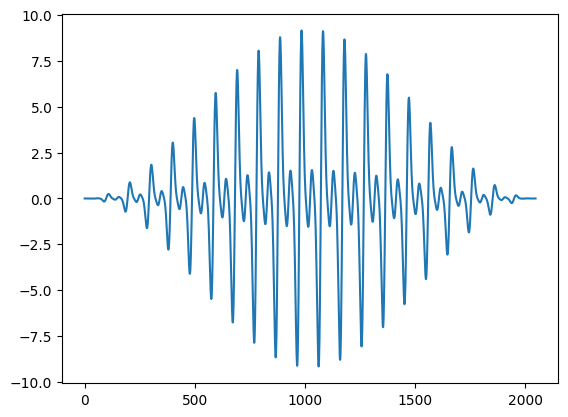

In [57]:
sample_points = adc(test_signal_func, FS, N_SAMPLES)
sample_points = dsp.arm_hanning_f32(N_SAMPLES) * sample_points
plt.plot(sample_points)
plt.show()

RFFT init status: 0
RFFT result: [-2.4223328e-04 -1.4305115e-06 -2.3667575e-04 ... -1.1805760e-05
  5.2100077e-06 -9.3897670e-06]
RFFT result length: 2048
RFFT magnitude length: 1024
Delta x: 500.0


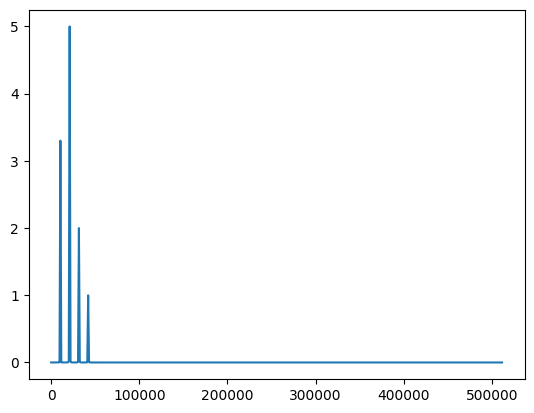

In [ ]:
rfftf32 = dsp.arm_rfft_fast_instance_f32()
status = dsp.arm_rfft_fast_init_f32(rfftf32, N_SAMPLES)
print(f"RFFT init status: {status}")

result = dsp.arm_rfft_fast_f32(rfftf32, sample_points, 0)
# print(f"RFFT result: {result}")
print(f"RFFT result length: {len(result)}")

result /= N_SAMPLES

mag = dsp.arm_cmplx_mag_f32(result) * 2 * 2
# print(f"RFFT magnitude: {mag}")
print(f"RFFT magnitude length: {len(mag)}")
x_axis = np.arange(0, N_SAMPLES // 2) / N_SAMPLES * FS

delta_x = x_axis[1] - x_axis[0]
print(f"Delta x: {delta_x}")

plt.plot(x_axis, mag)
plt.show()


Inverse RFFT result length: 2048


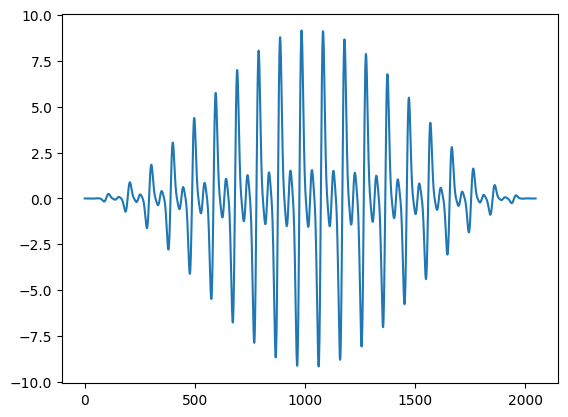

In [59]:
result *= N_SAMPLES
result = dsp.arm_rfft_fast_f32(rfftf32, result, 1)
print(f"Inverse RFFT result length: {len(result)}")
plt.plot(result)
plt.show()